# Training the DOA networks

Trains the networks listed in `MODELS`, each saved to `models/<name>/`. The two used in `HW5.ipynb` are the paper's network (Fig. 1, with input normalization) for each scenario:
* **A**: FOV 50°, amplitudes $U[0.5, 1.5]$ (paper Figs. 3, 6, 7) → `models/A/`
* **B**: FOV 20°, equal gains (paper Fig. 2) → `models/B/`

Every step uses a fresh batch of 4000 realizations simulated on the GPU (number of sources uniform over 1–4, SNR spread evenly over `SNR_RANGE`). Training uses Adam; the learning rate is multiplied by 0.7 after 8000 steps without validation improvement, and the paper's loss: cross entropy plus the root of the closest-estimate MSE (Eq. 3) of each DOA head. Each network takes ~25 min on an RTX 5070. Its folder holds `best.pth` (lowest validation loss), `last.pth`, `history.json` (learning curve), `train.log` and `checkpoint.pth`. An interrupted run continues from `checkpoint.pth` when trained again; delete the folder to start over.

In [1]:
%load_ext autoreload
%autoreload 2

import json

import torch

from src.models import BaseDOAModel, ResidualHeadModel
from src.evaluation import evaluate_per_snr, plot_learning_curve, plot_results
from src.data_generation import SCENARIOS
from src.trainer import make_sampler, train

In [2]:
# Shared settings
STEPS = 150_000
LR = 1e-3
BATCH_SIZE = 4000        # paper
EVAL_EVERY = 2000        # steps
VAL_SIZE = 40_000        # fixed validation set
SNR_RANGE = (0.0, 40.0)  # training SNRs [dB]
SEED = 0                 # model initialization

In [3]:
# name: train (True) or load saved (False), scenario, network
torch.manual_seed(SEED)
MODELS = {
    "A": dict(train=False, scenario="A", model=BaseDOAModel(d_model=32, input_norm=True)),
    "B": dict(train=False, scenario="B", model=BaseDOAModel(d_model=32, input_norm=True)),
    "A_res": dict(train=True, scenario="A", model=ResidualHeadModel(d_model=32, input_norm=True)),
}

In [4]:
for name, m in MODELS.items():
    if m["train"]:
        print(f"Training model {name} for scenario {m['scenario']}...")
        sample = make_sampler(m["scenario"], SNR_RANGE)
        train(m["model"], sample, sample(VAL_SIZE, 0), STEPS, LR, SCENARIOS[m["scenario"]]["half_fov"], f"models/{name}",
              batch_size=BATCH_SIZE, eval_every=EVAL_EVERY)
    else:
        m["model"].load_state_dict(torch.load(f"models/{name}/best.pth"))

Training model A_res for scenario A...
steps 150000 | lr 0.001 | batch 4000 | parameters 4,136,270 | start at step 1
step   2000 | train 1.5369 | val 0.9964 | acc 0.663 | RMSE 2.013 deg
step   4000 | train 0.8502 | val 0.7409 | acc 0.756 | RMSE 1.327 deg
step   6000 | train 0.6980 | val 0.6785 | acc 0.788 | RMSE 1.182 deg
step   8000 | train 0.6520 | val 0.6290 | acc 0.802 | RMSE 1.081 deg
step  10000 | train 0.6198 | val 0.5937 | acc 0.811 | RMSE 0.987 deg
step  12000 | train 0.5949 | val 0.5907 | acc 0.817 | RMSE 0.996 deg
step  14000 | train 0.5794 | val 0.5641 | acc 0.825 | RMSE 0.916 deg
step  16000 | train 0.5681 | val 0.5563 | acc 0.828 | RMSE 0.910 deg
step  18000 | train 0.5591 | val 0.5571 | acc 0.829 | RMSE 0.915 deg
step  20000 | train 0.5546 | val 0.5623 | acc 0.825 | RMSE 0.905 deg
step  22000 | train 0.5458 | val 0.5343 | acc 0.835 | RMSE 0.861 deg
step  24000 | train 0.5402 | val 0.5334 | acc 0.838 | RMSE 0.868 deg
step  26000 | train 0.5359 | val 0.5363 | acc 0.838 | R

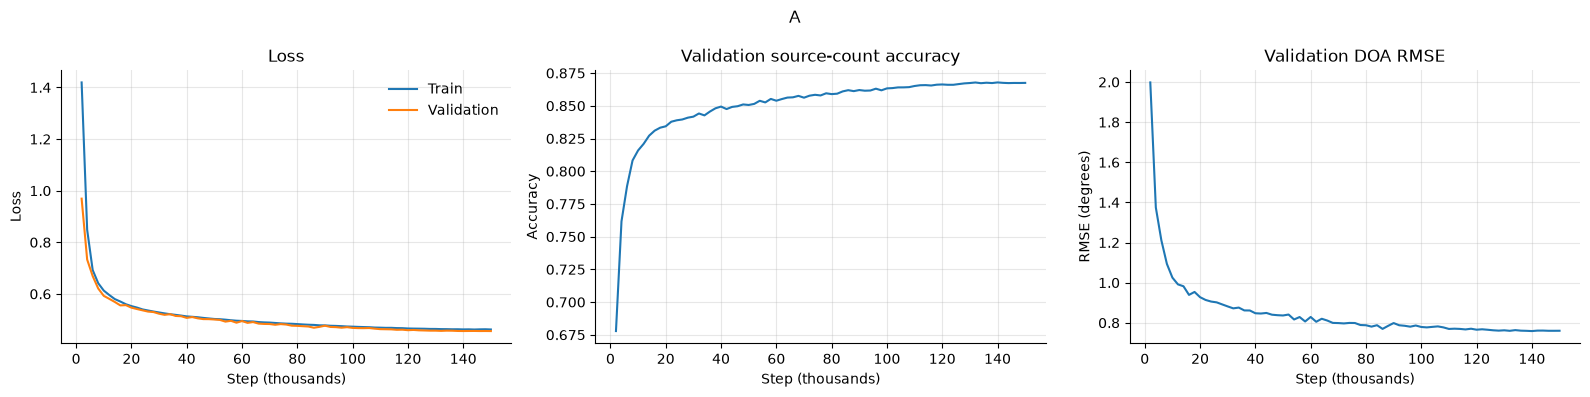

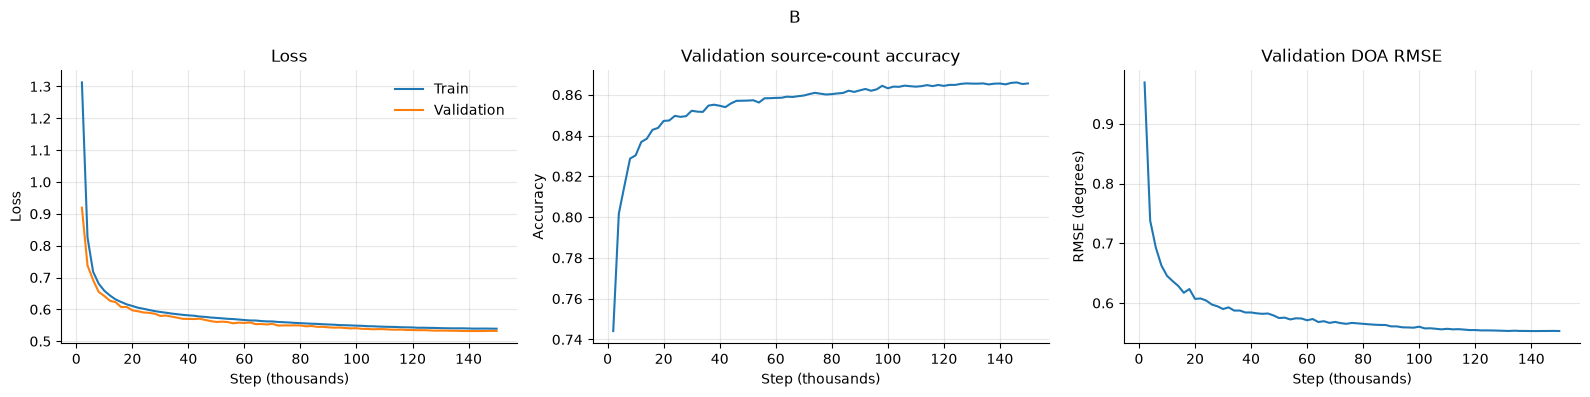

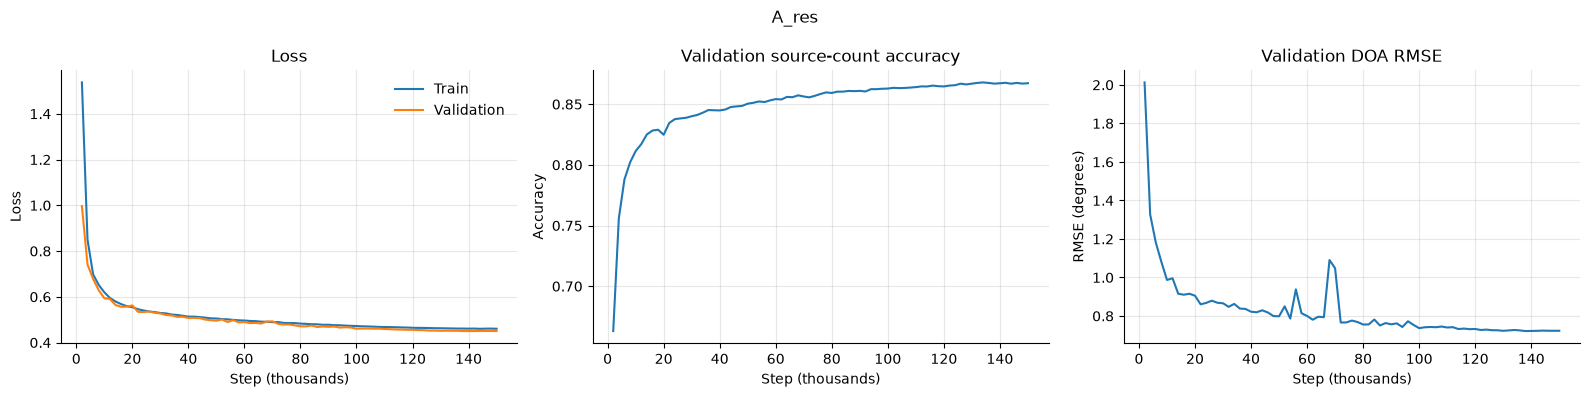

In [5]:
for name in MODELS:
    with open(f"models/{name}/history.json") as f:
        plot_learning_curve(json.load(f), title=name)

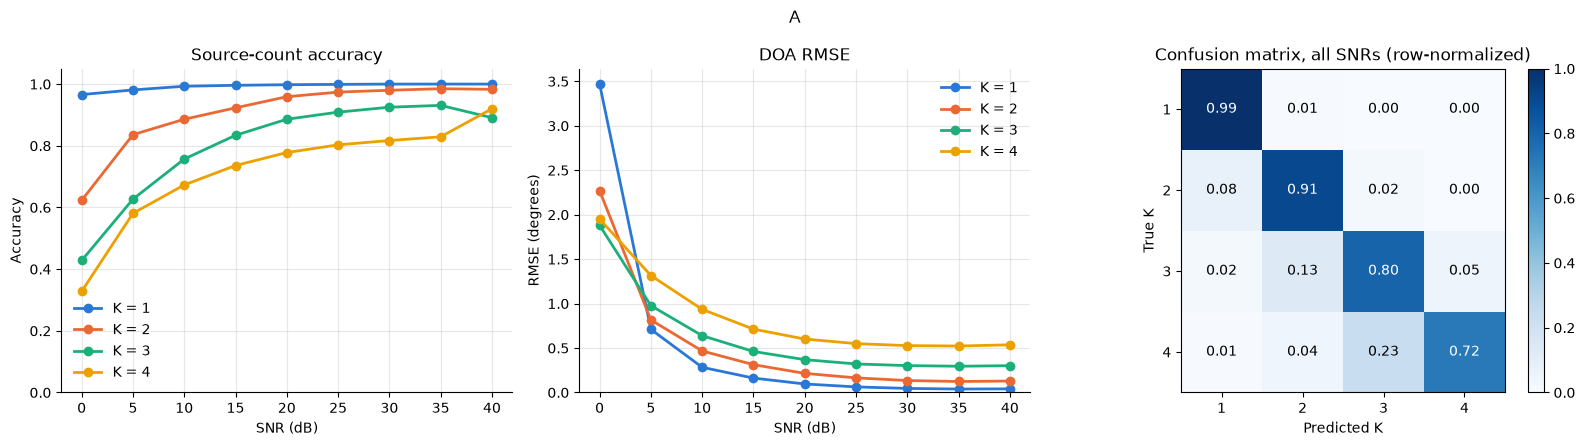

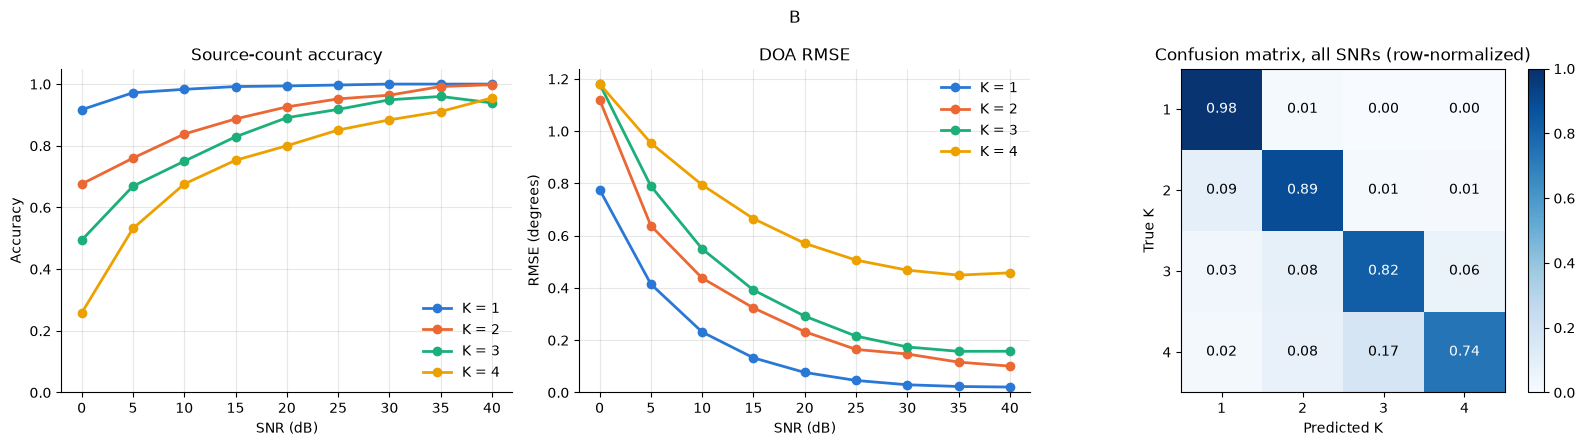

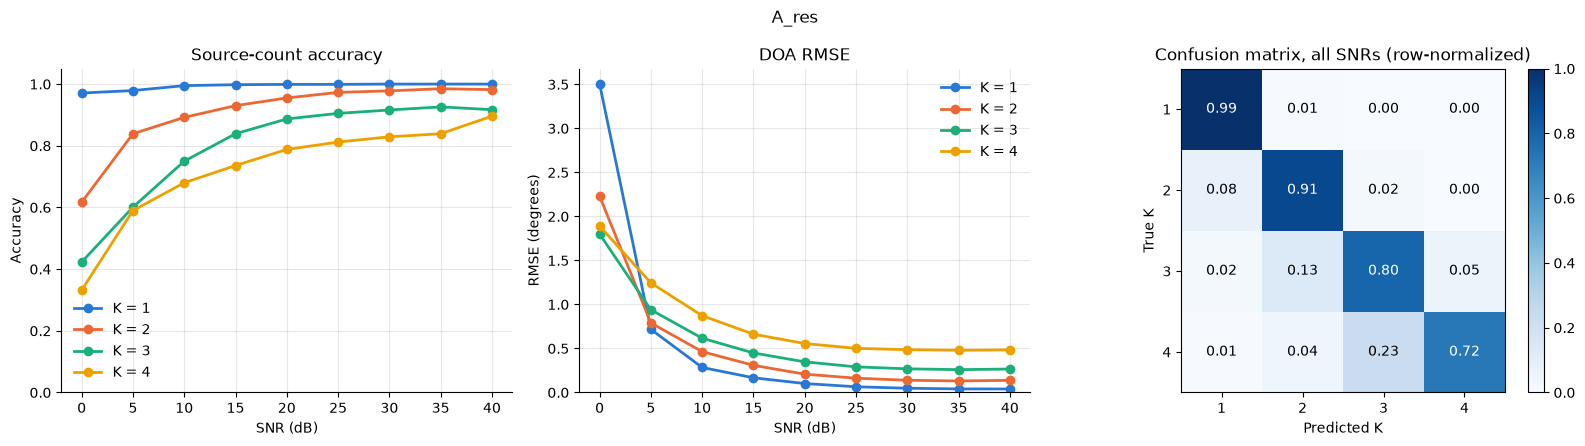

In [6]:
for name, m in MODELS.items():
    plot_results(evaluate_per_snr(m["model"], m["scenario"]), title=name)